# Handwritten Digit Recognition with Convolutional Neural Networks

Train and evaluate a convolutional neural network on the MNIST handwritten digit dataset.

**Tools:** Python, TensorFlow/Keras, scikit-learn, Matplotlib

## 1. Load the MNIST Data Set

In step 1, we are loading the MNIST dataset which contains grayscale images of handwritten digits from 0 to 9. The training set is so we can fit the model and the test set is used to evaluate the final performance.

In [1]:
# Import the required libraries for data handling, modeling, and evaluation.
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Set random seeds so the results are reproducible.
np.random.seed(42)
tf.random.set_seed(42)

# Load the MNIST handwritten digit dataset from TensorFlow/Keras.
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Display the original dataset shapes.
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)


## 2. Display the First Five Training Images and Labels

In step 2, we see that the first five training images are being displayed below and comparing it to the first five labels. Each of the labels are used for indentifying the correct digit shown in each of the images. 

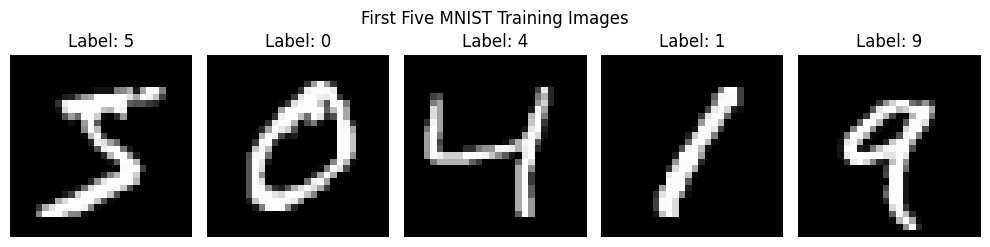

First five training labels: [5 0 4 1 9]


In [2]:
# Display the first five training images and compare them with the first five labels.
plt.figure(figsize=(10, 2.5))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("First Five MNIST Training Images")
plt.tight_layout()
plt.show()

print("First five training labels:", y_train[:5])

## 3. Preprocess the Image Data

In step 3, the pixel values are scaled from 0-255 to 0-1. Each of the images are reshaped so that they include a channel dimension due to CNN layers expect data in the following format '(height, width, channels)'.

In [3]:
# Normalize pixel values to the range 0 to 1.
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add a channel dimension for grayscale images: 28 x 28 x 1.
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Prepared training shape:", x_train.shape)
print("Prepared test shape:", x_test.shape)

Prepared training shape: (60000, 28, 28, 1)
Prepared test shape: (10000, 28, 28, 1)


## 4. Build and Train a CNN Classifier

In step 4, the CNN is using convolutional layers to learn the visual patterns and max pooling layers to reduce the image size but keeping the important features. The output layer has 10 units due to it having 10 possible digit classes.

In [4]:
# Build a convolutional neural network using TensorFlow/Keras.
model = models.Sequential([
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

# Compile the model using Adam optimizer and sparse categorical crossentropy.
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Display the model structure.
model.summary()

/opt/anaconda3/envs/mnist_cnn/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    x_train[:10000], y_train[:10000],
    epochs=2,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8121 - loss: 0.6209 - val_accuracy: 0.9430 - val_loss: 0.1743
Epoch 2/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9501 - loss: 0.1710 - val_accuracy: 0.9660 - val_loss: 0.1141


## 5. Report the Test Accuracy

In step 5, we are using the test set after the training phase to evaluate the model on images that it hasn't learned from. This allows us to get a better estimate for how well the model is going to perform on new handwritten digit images.

In [6]:
# Evaluate the trained CNN on the test set.
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.1107
Test accuracy: 0.9666


## 6. Display a Confusion Matrix on the Test Set Classifications

In step 6, we are using the confusion matrix to compare the true test labels to the model's predicted labels. If the predictions are correct, they'll appear on the diagonal. Off diagonal values will show where the model is confusing a digit. 

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


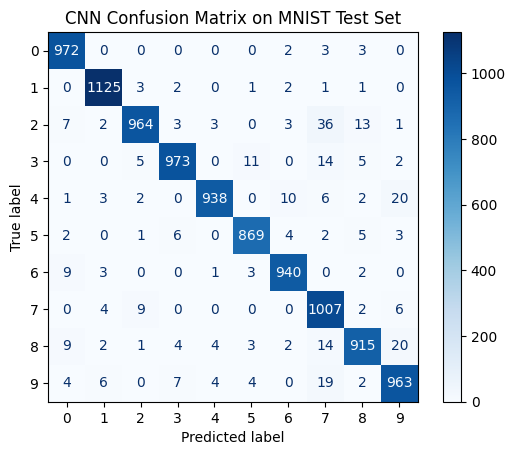

In [7]:
# Generate class predictions for the test images.
y_prob = model.predict(x_test)
y_pred = np.argmax(y_prob, axis=1)

# Create and display the confusion matrix.
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix on MNIST Test Set")
plt.show()

## 7. Classification Report

In [8]:
# Display precision, recall, and F1-score for each digit class.
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9681    0.9918    0.9798       980
           1     0.9825    0.9912    0.9868      1135
           2     0.9787    0.9341    0.9559      1032
           3     0.9779    0.9634    0.9706      1010
           4     0.9874    0.9552    0.9710       982
           5     0.9753    0.9742    0.9748       892
           6     0.9761    0.9812    0.9787       958
           7     0.9138    0.9796    0.9455      1028
           8     0.9632    0.9394    0.9511       974
           9     0.9488    0.9544    0.9516      1009

    accuracy                         0.9666     10000
   macro avg     0.9672    0.9665    0.9666     10000
weighted avg     0.9671    0.9666    0.9666     10000



## Summary

The CNN was trained for **2 epochs** on a subset of 10,000 MNIST training images and achieved **96.66% test accuracy** on 10,000 held-out test images in the recorded run. The confusion matrix and class-wise precision, recall, and F1 scores show where digits were misclassified. These are recorded results; rerunning may yield different metrics.